In [1]:
pip install tensorflow roboflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.4/85.4 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.8/66.8 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.9/49.9 MB 15.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 60.7 MB/s eta 0:00:00
  Attempting uninstall: opencv-python-headless
    Found existing installation: opencv-python-headless 4.11.0.86
    Uninstalling opencv-python-headless-4.11.0.86:
      Successfully uninstalled opencv-python-headless-4.11.0.86
  Attempting uninstall: idna
    Found existing installation: idna 3.10
    Uninstalling idna-3.10:
      Successfully uninstalled idna-3.10


In [2]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing import image

In [3]:
from roboflow import Roboflow

import os
rf = Roboflow(api_key=os.environ["ROBOFLOW_API_KEY"])  # set your own key

project = rf.workspace("meva-wfywb").project("fish-fresh-and-non-fresh")

version = project.version(1)

dataset = version.download("folder")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to FISH-FRESH-AND-NON-FRESH-1 in folder:: 100%|██████████| 4303/4303 [00:00<00:00, 6924.77it/s]


In [4]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Image Augmentation for training with validation split
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2  # 20% of training data used for validation
)

# Validation data generator (only rescaling)
val_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

# Test data generator (only rescaling)
test_datagen = ImageDataGenerator(rescale=1./255)

# Load and split training data
train_generator = train_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/train',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='training'  # Training subset
)

val_generator = val_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/valid',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    subset='validation'  # Validation subset
)

# Load test data
test_generator = test_datagen.flow_from_directory(
    '/content/FISH-FRESH-AND-NON-FRESH-1/test',
    target_size=(224, 224),
    batch_size=32,
    class_mode='binary',
    shuffle=False  # Important for consistent evaluation
)

print(f"Training samples: {train_generator.samples}")
print(f"Validation samples: {val_generator.samples}")
print(f"Test samples: {test_generator.samples}")


Found 2406 images belonging to 2 classes.
Found 171 images belonging to 2 classes.
Found 426 images belonging to 2 classes.
Training samples: 2406
Validation samples: 171
Test samples: 426


In [5]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Define the CNN model
model_3 = Sequential([
    Conv2D(32, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.0005), input_shape=(224, 224, 3)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.0005)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same', kernel_regularizer=l2(0.0005)),
    BatchNormalization(),
    MaxPooling2D(pool_size=(2, 2)),

    Flatten(),
    Dense(256, activation='relu', kernel_regularizer=l2(0.0005)),
    Dropout(0.5),

    Dense(1, activation='sigmoid')  # Binary classification
])

# Optimizer
optimizer = Adam(learning_rate=0.0003, beta_1=0.9, beta_2=0.999)

# Compile the model
model_3.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=6, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=3, verbose=1)

# Summary
model_3.summary()

# Training (example)
# history = model.fit(train_data, validation_data=val_data, epochs=50, callbacks=[early_stop, reduce_lr])


Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 100352)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    25,690,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25,784,769 (98.36 MB)

 Trainable params: 25,784,321 (98.36 MB)

 Non-trainable params: 448 (1.75 KB)

In [6]:
history = model_3.fit(
    train_generator,
    epochs=50,
    validation_data=test_generator
)

Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.


Epoch 1/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 52s 537ms/step - accuracy: 0.7743 - loss: 3.3303 - val_accuracy: 0.4836 - val_loss: 8.9260
Epoch 2/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 449ms/step - accuracy: 0.8624 - loss: 0.8964 - val_accuracy: 0.4836 - val_loss: 9.6840
Epoch 3/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 33s 443ms/step - accuracy: 0.8964 - loss: 0.6445 - val_accuracy: 0.4859 - val_loss: 9.7810
Epoch 4/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 35s 452ms/step - accuracy: 0.9016 - loss: 0.6111 - val_accuracy: 0.5282 - val_loss: 6.8984
Epoch 5/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 446ms/step - accuracy: 0.9231 - loss: 0.5374 - val_accuracy: 0.5751 - val_loss: 7.1562
Epoch 6/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 446ms/step - accuracy: 0.9255 - loss: 0.5600 - val_accuracy: 0.6714 - val_loss: 3.2580
Epoch 7/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 440ms/step - accuracy: 0.9184 - loss: 0.5580 - val_accuracy: 0.8052 - val_loss: 1.0159
Epoch 8/50
76/76 ━━━━━━━━━━━━━━━━━━━━ 34s 446ms/step - accuracy: 0.9486 - loss: 0.4676 - val_accu

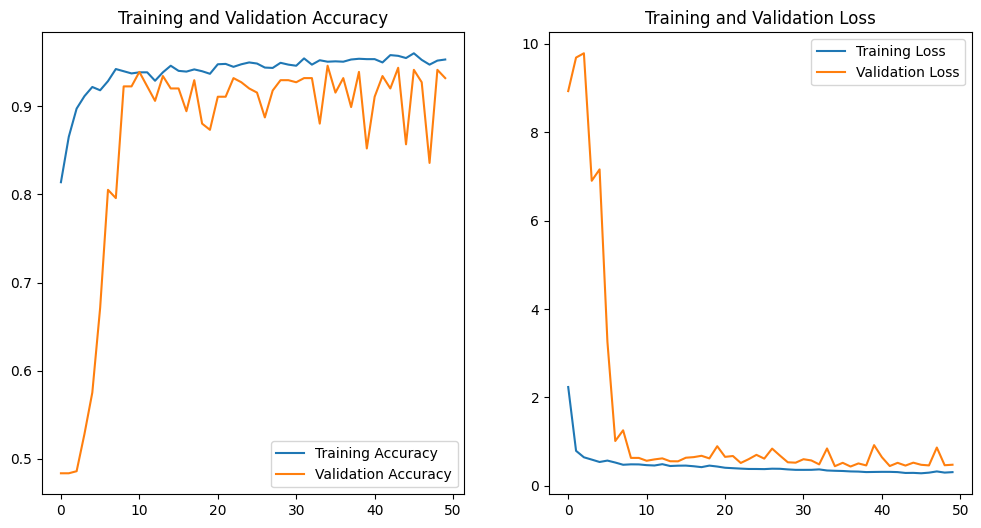

14/14 ━━━━━━━━━━━━━━━━━━━━ 1s 73ms/step - accuracy: 0.9062 - loss: 0.6440
Test Loss: 0.4791
Test Accuracy: 0.9319
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 102ms/step

Classification Report:
                precision    recall  f1-score   support

    Fresh Fish       0.94      0.93      0.93       220
Non Fresh Fish       0.92      0.94      0.93       206

      accuracy                           0.93       426
     macro avg       0.93      0.93      0.93       426
  weighted avg       0.93      0.93      0.93       426


Confusion Matrix:
[[204  16]
 [ 13 193]]


In [7]:
# prompt: grnarate modle loss and acuracy curve with accuracy report

import matplotlib.pyplot as plt
# Plotting training and validation loss and accuracy
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(len(acc))

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

# Accuracy Report
loss, accuracy = model_3.evaluate(test_generator)
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}")

from sklearn.metrics import classification_report, confusion_matrix

# Predict the classes for the test set
test_predictions = model_3.predict(test_generator)
test_predictions = (test_predictions > 0.5).astype(int) # Convert probabilities to binary predictions

# Get the true labels from the test generator
test_labels = test_generator.classes

# Get the class names
class_names = list(test_generator.class_indices.keys())

# Print classification report
print("\nClassification Report:")
print(classification_report(test_labels, test_predictions, target_names=class_names))

# Print confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(test_labels, test_predictions))
